# Klotski solver

Mohammadreza Mousazadehzarajabad, Computational Intelligence 2026/27

The goal is to move the target piece onto the exit at the bottom of the board using as few moves as possible.
A move slides one piece by one cell. I solve the six instances with BFS and with A* and compare the two.

In [1]:
import heapq
import time
from collections import deque

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

## Reading the instances

Each board line is split on spaces, so piece names with more than one character (like `10` in p02) work.
Exit columns are counted from 0.

In [3]:
def read_problems(path):
    problems = []
    lines = open(path).read().splitlines()
    i = 0
    while i < len(lines):
        if lines[i].startswith("problem"):
            p = {"id": lines[i].split()[1], "grid": []}
            i += 1
            while not lines[i].startswith("="):
                key, *values = lines[i].split()
                if key == "size":
                    p["rows"], p["cols"] = int(values[0]), int(values[1])
                elif key == "exit":
                    p["exit"] = [int(v) for v in values[1:]]
                elif key == "target":
                    p["target"] = values[0]
                i += 1
            i += 1
            while not lines[i].startswith("="):
                p["grid"].append(lines[i].split())
                i += 1
            problems.append(p)
        i += 1
    return problems


problems = read_problems("klotski-instances.txt")

## State, moves and goal

A state only stores where the pieces are. Pieces with the same shape are interchangeable, so for each shape
I keep a sorted tuple with the positions (top-left cell) of those pieces. The target is kept apart as the first group.
Without this, swapping two identical blocks would count as a new state

A piece can move one cell up, down, left or right if it stays on the board and the cells it moves into are free.
The puzzle is solved when the target is on the bottom row, under the exit.

In [4]:
class Klotski:
    def __init__(self, p):
        self.name = p["id"]
        self.rows, self.cols = p["rows"], p["cols"]
        cells = {}
        for r, row in enumerate(p["grid"]):
            for c, token in enumerate(row):
                if token != ".":
                    cells.setdefault(token, []).append((r, c))
        groups = {}
        for token, piece in cells.items():
            top = min(r for r, _ in piece)
            left = min(c for _, c in piece)
            shape = (max(r for r, _ in piece) - top + 1, max(c for _, c in piece) - left + 1)
            if token == p["target"]:
                target_shape, target_pos = shape, (top, left)
            else:
                groups.setdefault(shape, []).append((top, left))
        self.shapes = [target_shape] + sorted(groups)
        self.start = ((target_pos,),) + tuple(tuple(sorted(groups[s])) for s in self.shapes[1:])
        self.goal = (self.rows - target_shape[0], min(p["exit"]))

    def pieces(self, state):
        for g, positions in enumerate(state):
            for pos in positions:
                yield g, pos

    def cells(self, g, pos):
        h, w = self.shapes[g]
        return {(pos[0] + i, pos[1] + j) for i in range(h) for j in range(w)}

    def next_states(self, state):
        occupied = set()
        for g, pos in self.pieces(state):
            occupied |= self.cells(g, pos)
        for g, pos in self.pieces(state):
            h, w = self.shapes[g]
            own = self.cells(g, pos)
            for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
                new = (pos[0] + dr, pos[1] + dc)
                if not (0 <= new[0] <= self.rows - h and 0 <= new[1] <= self.cols - w):
                    continue
                if (self.cells(g, new) - own) & occupied:
                    continue
                group = tuple(sorted([q for q in state[g] if q != pos] + [new]))
                yield state[:g] + (group,) + state[g + 1:]

    def solved(self, state):
        return state[0][0] == self.goal

    def h(self, state):
        (r, c), (gr, gc) = state[0][0], self.goal
        exit_cells = self.cells(0, self.goal)
        blockers = sum(1 for g, pos in self.pieces(state) if g > 0 and self.cells(g, pos) & exit_cells)
        return abs(r - gr) + abs(c - gc) + blockers

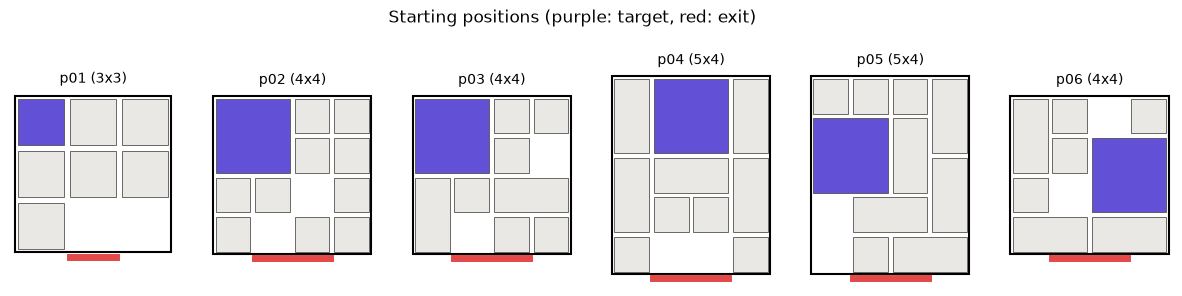

In [5]:
def draw(ax, game, state, title=""):
    ax.add_patch(Rectangle((0, 0), game.cols, game.rows, fill=False, linewidth=1.5))
    for g, (r, c) in game.pieces(state):
        h, w = game.shapes[g]
        color = "#6250d6" if g == 0 else "#e9e8e4"
        ax.add_patch(Rectangle((c + 0.06, r + 0.06), w - 0.12, h - 0.12, facecolor=color, edgecolor="#52514e", linewidth=0.6))
    left, width = game.goal[1], game.shapes[0][1]
    ax.plot([left + 0.05, left + width - 0.05], [game.rows + 0.1] * 2, color="#e34948", linewidth=5)
    ax.set_xlim(-0.1, game.cols + 0.1)
    ax.set_ylim(game.rows + 0.3, -0.1)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=10)


games = [Klotski(p) for p in problems]
fig, axes = plt.subplots(1, len(games), figsize=(15, 3.5))
for ax, game in zip(axes, games):
    draw(ax, game, game.start, f"{game.name} ({game.rows}x{game.cols})")
fig.suptitle("Starting positions (purple: target, red: exit)")
plt.show()

## Search

BFS explores the states in order of distance from the start, so the first solution it finds is a shortest one.

A* always expands the state with the smallest g + h, where g is the number of moves made so far and h is an estimate
of the moves still needed. h is the Manhattan distance from the target to the exit plus the number of other pieces
lying on the exit cells. it never overestimates: the target moves at most one cell per move, and every piece on the
exit has to move at least once. it is also consistent (one move changes h by at most one), so A* returns a
shortest solution without reopening states.

If the queue runs out before the goal is reached, there is no solution.

In [6]:
def path_to(parent, state):
    path = []
    while state is not None:
        path.append(state)
        state = parent[state]
    return path[::-1]


def bfs(game):
    parent = {game.start: None}
    queue = deque([game.start])
    while queue:
        state = queue.popleft()
        if game.solved(state):
            return path_to(parent, state), len(parent)
        for nxt in game.next_states(state):
            if nxt not in parent:
                parent[nxt] = state
                queue.append(nxt)
    return None, len(parent)


def astar(game):
    parent = {game.start: None}
    cost = {game.start: 0}
    frontier = [(game.h(game.start), 0, game.start)]
    closed = set()
    while frontier:
        _, g, state = heapq.heappop(frontier)
        if state in closed:
            continue
        closed.add(state)
        if game.solved(state):
            return path_to(parent, state), len(parent)
        for nxt in game.next_states(state):
            if g + 1 < cost.get(nxt, float("inf")):
                cost[nxt] = g + 1
                parent[nxt] = state
                heapq.heappush(frontier, (g + 1 + game.h(nxt), g + 1, nxt))
    return None, len(parent)

## Results

"states" is the number of different states the search generated.

In [7]:
results = {}
print(f"{'':5}{'':6}{'moves':>7}{'states':>10}{'time (s)':>10}")
for game in games:
    for name, search in (("BFS", bfs), ("A*", astar)):
        start = time.perf_counter()
        path, states = search(game)
        seconds = time.perf_counter() - start
        moves = len(path) - 1 if path else None
        results[game.name, name] = (moves, states, path)
        print(f"{game.name:5}{name:6}{str(moves):>7}{states:>10,}{seconds:>10.2f}")
    assert results[game.name, "BFS"][0] == results[game.name, "A*"][0]

             moves    states  time (s)
p01  BFS         8       143      0.01
p01  A*          8       102      0.01
p02  BFS        18       266      0.02
p02  A*         18       227      0.02
p03  BFS        45     2,153      0.10
p03  A*         45     2,097      0.11
p04  BFS       116    24,109      1.32
p04  A*        116    23,837      1.60
p05  BFS       179    40,600      2.11
p05  A*        179    38,107      2.49
p06  BFS      None       833      0.04
p06  A*       None       833      0.04


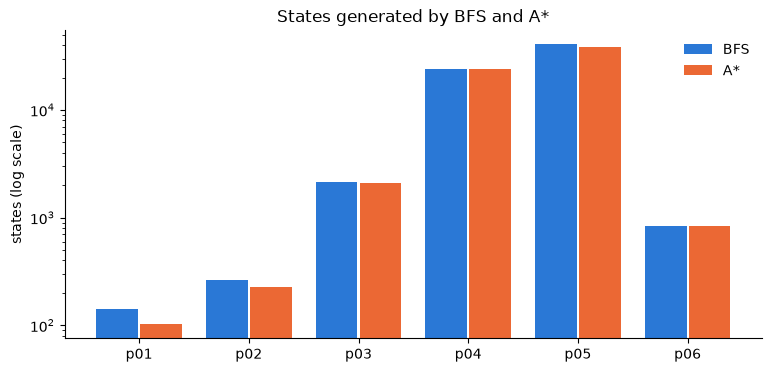

In [8]:
names = [game.name for game in games]
x = range(len(names))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar([i - 0.2 for i in x], [results[n, "BFS"][1] for n in names], 0.38, color="#2a78d6", label="BFS")
ax.bar([i + 0.2 for i in x], [results[n, "A*"][1] for n in names], 0.38, color="#eb6834", label="A*")
ax.set_yscale("log")
ax.set_xticks(list(x), names)
ax.set_ylabel("states (log scale)")
ax.set_title("States generated by BFS and A*")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

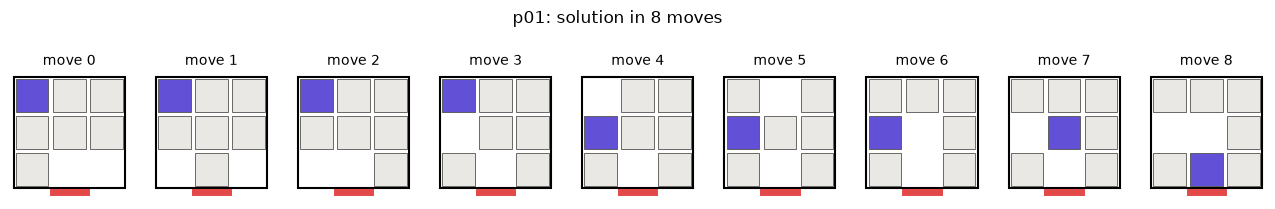

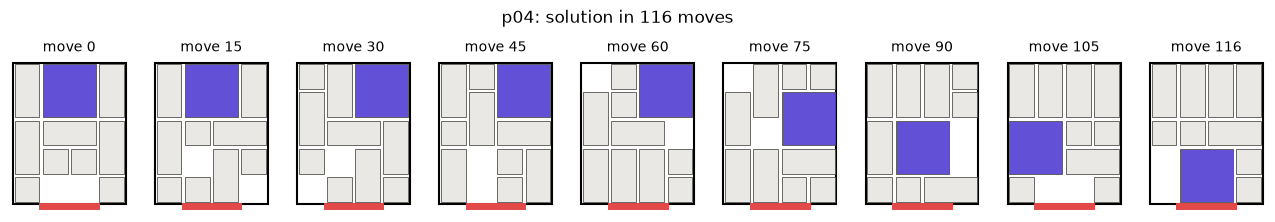

In [9]:
def show_solution(game, every=1, columns=9):
    path = results[game.name, "A*"][2]
    steps = list(range(0, len(path), every))
    if steps[-1] != len(path) - 1:
        steps.append(len(path) - 1)
    steps = steps[:columns - 1] + [steps[-1]] if len(steps) > columns else steps
    fig, axes = plt.subplots(1, len(steps), figsize=(1.8 * len(steps), 2.6))
    for ax, k in zip(axes, steps):
        draw(ax, game, path[k], f"move {k}")
    fig.suptitle(f"{game.name}: solution in {len(path) - 1} moves")
    plt.show()


show_solution(games[0])
show_solution(games[3], every=15)

## Observations

- BFS and A* give the same number of moves on every instance, which is a good check that the heuristic is admissible.
- A* generates fewer states than BFS. The gain is clear on the small boards but small on p04 and p05: the target is only
  3 cells away from the exit, while most of the moves are needed to move the other pieces out of the way, and the
  heuristic cannot see that.
- p06 has no solution. Both searches go through all the reachable states and stop, so the answer is None.
- I count the exit columns from 0. Counting from 1 gives different answers; with 0 the exit of p04 is under the two
  middle columns, as in the classic Klotski, and the result (116 moves) matches the known optimum.